1. Построение базовой модели 

In [84]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from helper import load_clean_data, get_preprocessor
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
from sklearn.tree import plot_tree

In [86]:
SEED = 42
np.random.seed(SEED)

In [87]:
df = load_clean_data()
X, y = df.drop(columns=["annual_medical_cost"]), df["annual_medical_cost"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

cv_KFold = KFold(n_splits=5, shuffle=True, random_state=SEED)

1.1 Dummy regressor

Для начала пробуем модель, которая предсказывает среднее значение по всей тренировочной выборке 

In [88]:
#собираем препроцессор и модель в один пайплайн
dummy_pipe = Pipeline([
   ("prep", get_preprocessor(X_train=X_train)),
   ("model", DummyRegressor(strategy="mean")) 
])

#оцениваем через KFold кросс-валидацию
scoring = ["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]
cv_res = cross_validate(dummy_pipe, X_train, y_train, cv=cv_KFold, scoring=scoring)

#выводим средние метрики по 5 фолдам и делаем вывод без отрицательных значений 
{m.replace("neg_", ""): (-cv_res[f"test_{m}"].mean() if m.startswith("neg_") else cv_res[f"test_{m}"].mean().round(3)) for m in scoring }

{'root_mean_squared_error': np.float64(3123.8169283363254),
 'mean_absolute_error': np.float64(1991.7514681473476),
 'r2': np.float64(-0.0)}

Модель, предсказывая среднее, очевидно будет иметь R2 = 0, то есть она не объясняет дисперсию в данных. MAE и RMSE сейчас тяжело оценить,
нужно сравнивать с другими моделями

1.2 Линейная регрессия 

In [89]:
#собираем препроцессор и модель в один пайплайн
linear_pipe = Pipeline([
   ("prep", get_preprocessor(X_train=X_train)),
   ("model", LinearRegression()) 
])

#оцениваем через KFold кросс-валидацию
scoring = ["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]
cv_res = cross_validate(linear_pipe, X_train, y_train, cv=cv_KFold, scoring=scoring)

#выводим средние метрики по 5 фолдам и делаем вывод без отрицательных значений 
{m.replace("neg_", ""): (-cv_res[f"test_{m}"].mean() if m.startswith("neg_") else cv_res[f"test_{m}"].mean().round(3)) for m in scoring }

{'root_mean_squared_error': np.float64(1863.791421920152),
 'mean_absolute_error': np.float64(1130.8889897917768),
 'r2': np.float64(0.643)}

Линейная регрессия уже выдает метрики лучше, RMSE и MAE меньше, чем у Dummy Regressor, R2 = 0.6 , что неплохо для линейной модели 

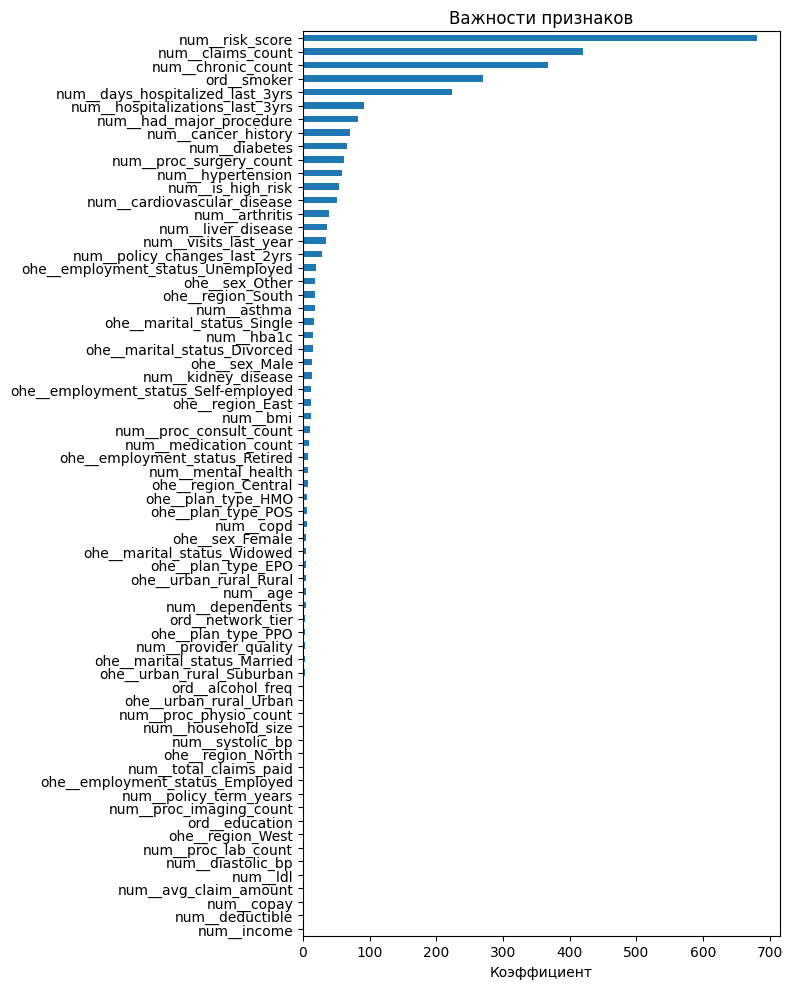

In [90]:
linear_pipe.fit(X_train, y_train)

#имена признаков после препроцессинга
feature_names = linear_pipe.named_steps["prep"].get_feature_names_out()

#коэффициенты важности признаков 
coefs = linear_pipe.named_steps["model"].coef_

# переводим в Series и сортируем по значению
importance = pd.Series(np.abs(coefs), index=feature_names).sort_values()

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [91]:
coef_table = pd.DataFrame({
    "feature": feature_names,
    "coef": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

coef_table.head(10)

,feature,coef,abs_coef
18,num__risk_score,680.742609,680.742609
19,num__claims_count,-419.248858,419.248858
22,num__chronic_count,366.705214,366.705214
64,ord__smoker,270.616971,270.616971
7,num__days_hospitalized_last_3yrs,223.724392,223.724392
6,num__hospitalizations_last_3yrs,90.766882,90.766882
39,num__had_major_procedure,82.205932,82.205932
28,num__cancer_history,70.555817,70.555817
24,num__diabetes,66.582512,66.582512
34,num__proc_surgery_count,-62.234893,62.234893


Для линейной регрессии самые важные признаки: risk_score, claims_count, chronic_count. Тут интересно, что количество жалоб снижает предпологаемую стоимость страховки, хотя по сути должно быть наоборот

1.3 Дерево решений

In [92]:
#собираем препроцессор и модель в один пайплайн
decision_tree_pipe = Pipeline([
   ("prep", get_preprocessor(X_train=X_train)),
   ("model", DecisionTreeRegressor(random_state=SEED, max_depth=4)) 
])

#оцениваем через KFold кросс-валидацию
scoring = ["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]
cv_res = cross_validate(decision_tree_pipe, X_train, y_train, cv=cv_KFold, scoring=scoring)

#выводим средние метрики по 5 фолдам и делаем вывод без отрицательных значений 
{m.replace("neg_", ""): (-cv_res[f"test_{m}"].mean() if m.startswith("neg_") else cv_res[f"test_{m}"].mean().round(3)) for m in scoring }

{'root_mean_squared_error': np.float64(1878.868602190445),
 'mean_absolute_error': np.float64(1122.1805450219847),
 'r2': np.float64(0.637)}

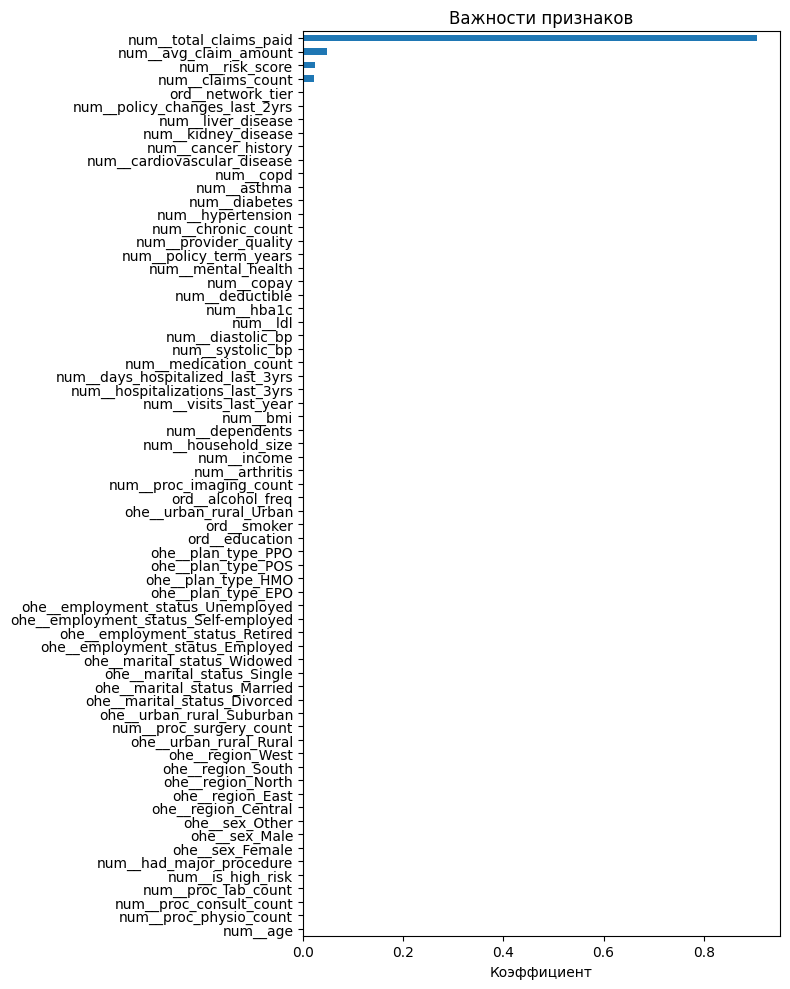

In [93]:
decision_tree_pipe.fit(X_train, y_train)

#имена признаков после препроцессинга
feature_names = decision_tree_pipe.named_steps["prep"].get_feature_names_out()

# переводим в Series и сортируем по значению
importance = pd.Series(decision_tree_pipe.named_steps["model"].feature_importances_, index=feature_names).sort_values()

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [94]:
importance_table = pd.DataFrame({
    "feature": feature_names,
    "importance": decision_tree_pipe.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)

importance_table.head(10)

,feature,importance
21,num__total_claims_paid,0.907021
20,num__avg_claim_amount,0.047780
18,num__risk_score,0.023845
19,num__claims_count,0.021353
45,ohe__region_North,0.000000
49,ohe__urban_rural_Suburban,0.000000
48,ohe__urban_rural_Rural,0.000000
47,ohe__region_West,0.000000
46,ohe__region_South,0.000000
0,num__age,0.000000


Для дерева решений самый важный признак: total_claims_paid, то есть почти за весь рост ожидаемой стоимости страховки отвечает сумма выплаченного по страховым случаям 

Визуализируем дерево 

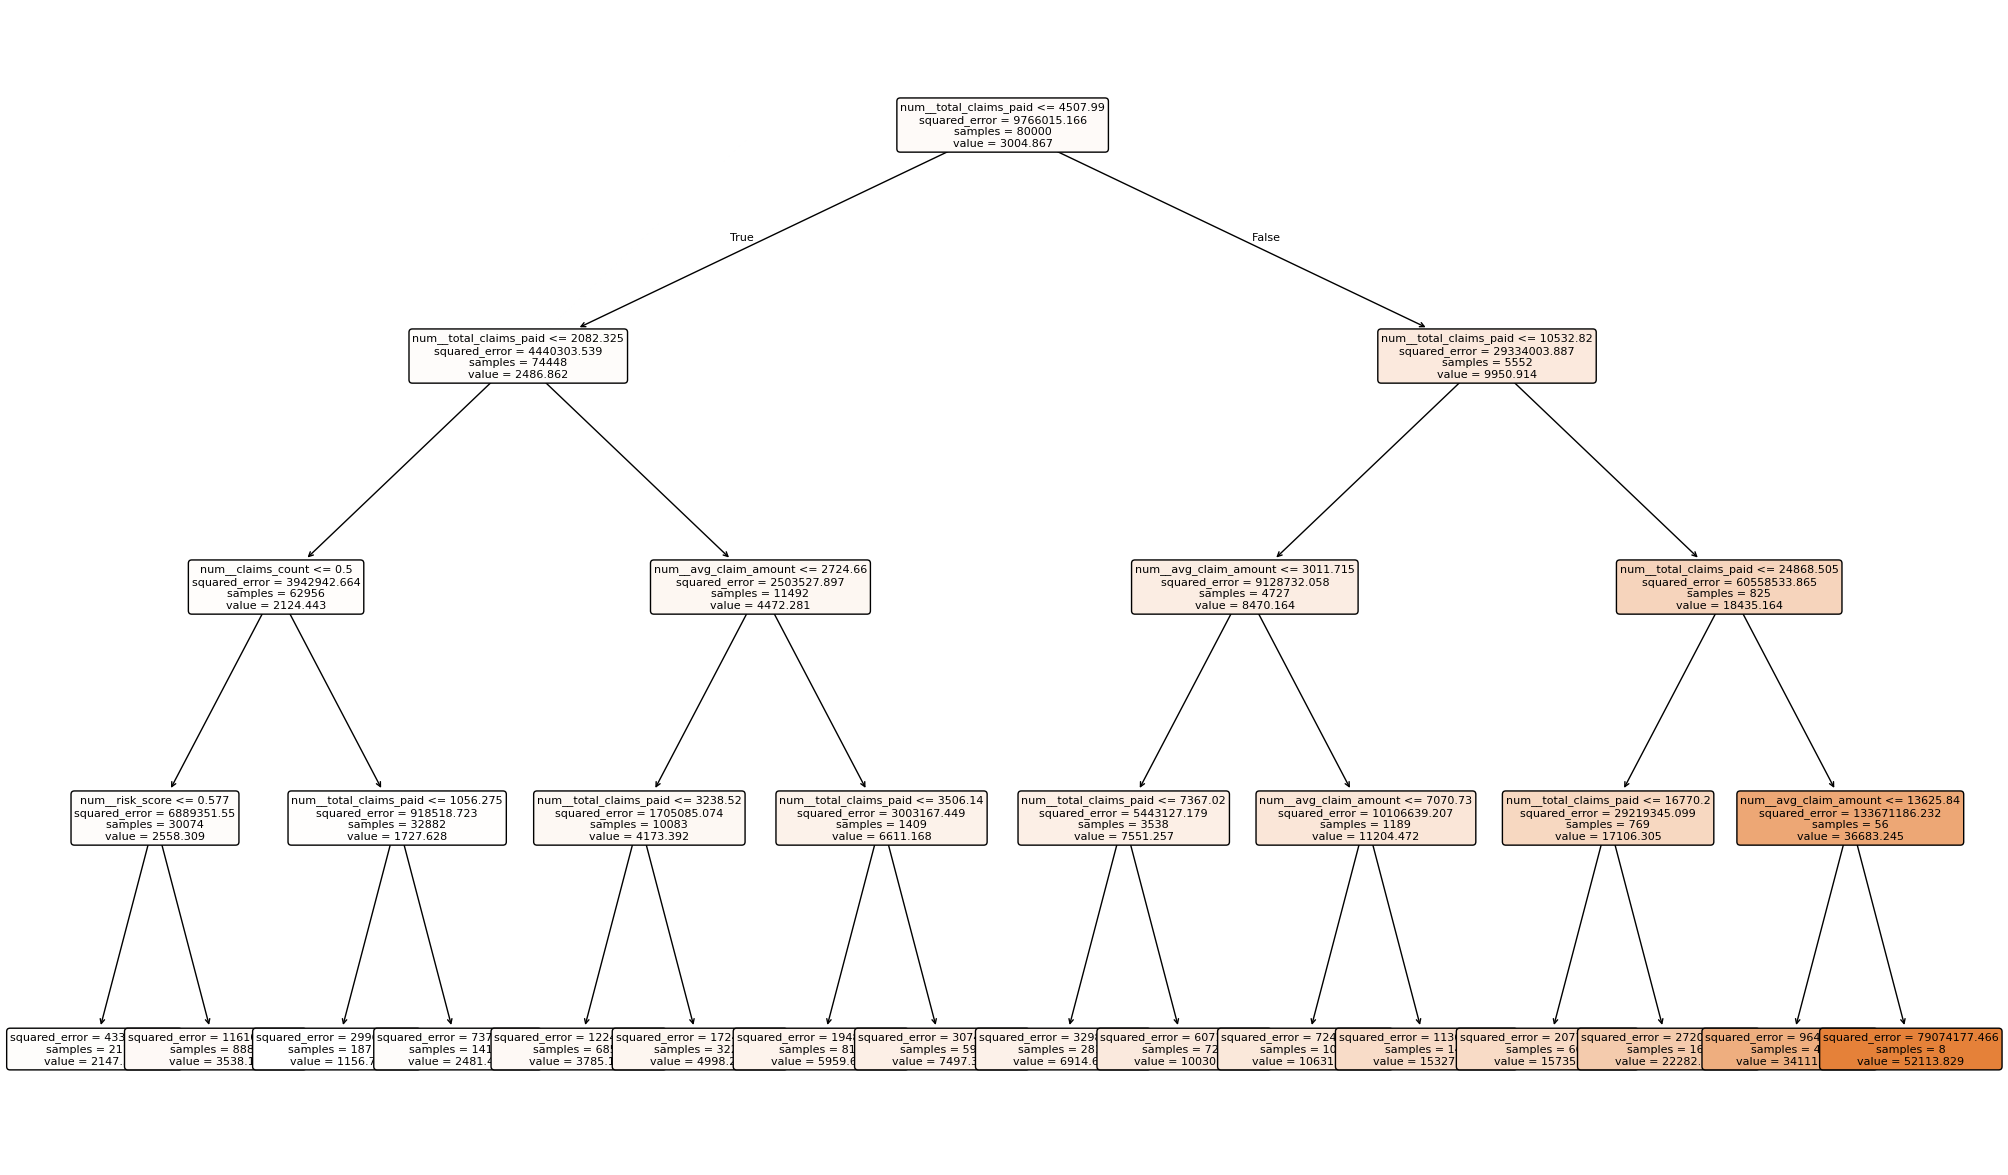

In [95]:
feature_names = decision_tree_pipe.named_steps["prep"].get_feature_names_out()

plt.figure(figsize=(25, 15))
plot_tree(
    decision_tree_pipe.named_steps["model"],
    feature_names=feature_names,
    filled=True,
    rounded=True,
    max_depth=4,        
    fontsize=8
)
plt.show()

1.4 Случайный лес 

In [96]:
random_forest_pipe = Pipeline([
    ("prep", get_preprocessor(X_train)),
    ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))
])

scoring = ["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]
cv_res = cross_validate(random_forest_pipe, X_train, y_train, cv=cv_KFold, scoring=scoring)

#выводим средние метрики по 5 фолдам и делаем вывод без отрицательных значений 
{m.replace("neg_", ""): (-cv_res[f"test_{m}"].mean() if m.startswith("neg_") else cv_res[f"test_{m}"].mean().round(3)) for m in scoring }

{'root_mean_squared_error': np.float64(1740.6193302944725),
 'mean_absolute_error': np.float64(1000.1955534074999),
 'r2': np.float64(0.689)}

На случайном лесе все метрики стали чуть лучше: MAE и MSE упали, R2 чуть увеличился 

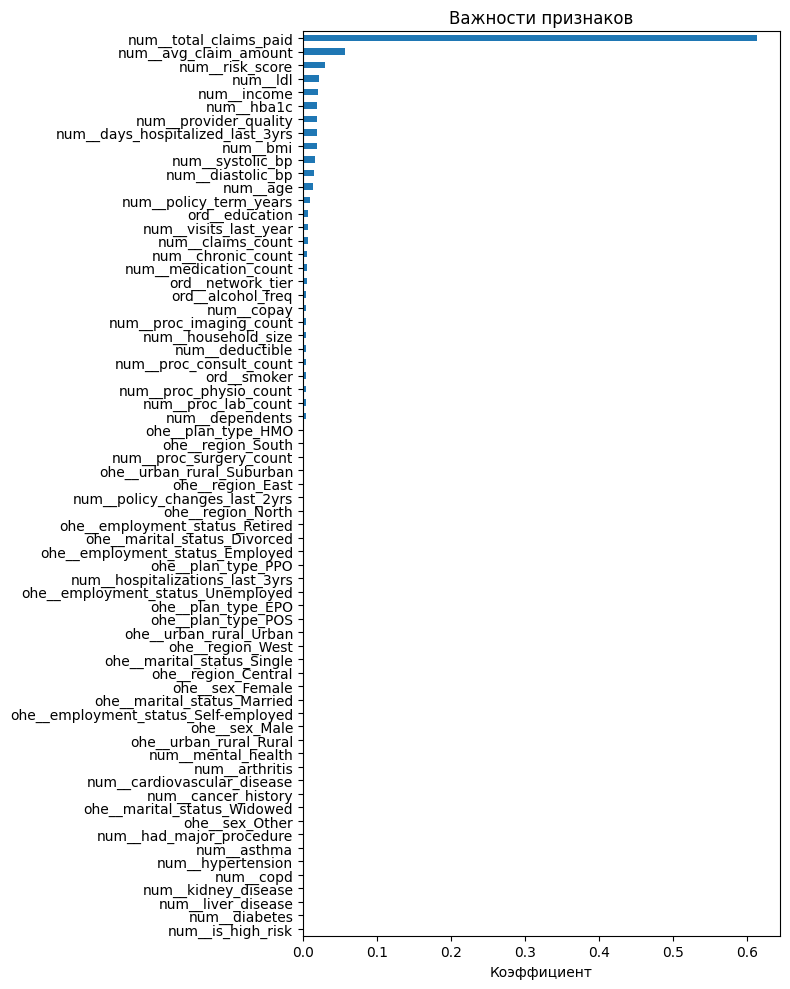

In [97]:
random_forest_pipe.fit(X_train, y_train)
#имена признаков после препроцессинга 
feature_names = random_forest_pipe.named_steps["prep"].get_feature_names_out()

# переводим в Series и сортируем по значению
importance = pd.Series(random_forest_pipe.named_steps["model"].feature_importances_, index=feature_names).sort_values()

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [98]:
importance_table = pd.DataFrame({
    "feature": feature_names,
    "importance": random_forest_pipe.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)

importance_table.head(10)

,feature,importance
21,num__total_claims_paid,0.614094
20,num__avg_claim_amount,0.057146
18,num__risk_score,0.030052
11,num__ldl,0.021425
1,num__income,0.020833
12,num__hba1c,0.019179
17,num__provider_quality,0.018965
7,num__days_hospitalized_last_3yrs,0.018582
4,num__bmi,0.018565
9,num__systolic_bp,0.015711


В случайном лесе самый важный признак: total_claims_paid. При одном дереве решений это тоже был самый важный признак, однако случайный лес еще распределил важность между другими признакаками

1.5 Градиентный бустинг

In [99]:
lgbm_pipe = Pipeline([
    ("prep", get_preprocessor(X_train)),
    ("model", LGBMRegressor(random_state=SEED))
])

cv_res = cross_validate(lgbm_pipe, X_train, y_train, cv=cv_KFold, scoring=scoring)

#средние метрики по фолдам
{m.replace("neg_", ""): (-cv_res[f"test_{m}"].mean() if m.startswith("neg_") else cv_res[f"test_{m}"].mean().round(3)) for m in scoring }

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003640 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2394
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3014.539480


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003212 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3016.241110


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003294 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2393
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2998.241664


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003270 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2396
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3000.553826


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003506 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2994.759390


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


{'root_mean_squared_error': np.float64(1727.4966934315185),
 'mean_absolute_error': np.float64(964.0877886171871),
 'r2': np.float64(0.694)}

При бустинге метрики стали еще чуть лучше: MSE и MAE упали, R2 вырос

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003824 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2398
[LightGBM] [Info] Number of data points in the train set: 80000, number of used features: 67
[LightGBM] [Info] Start training from score 3004.867094


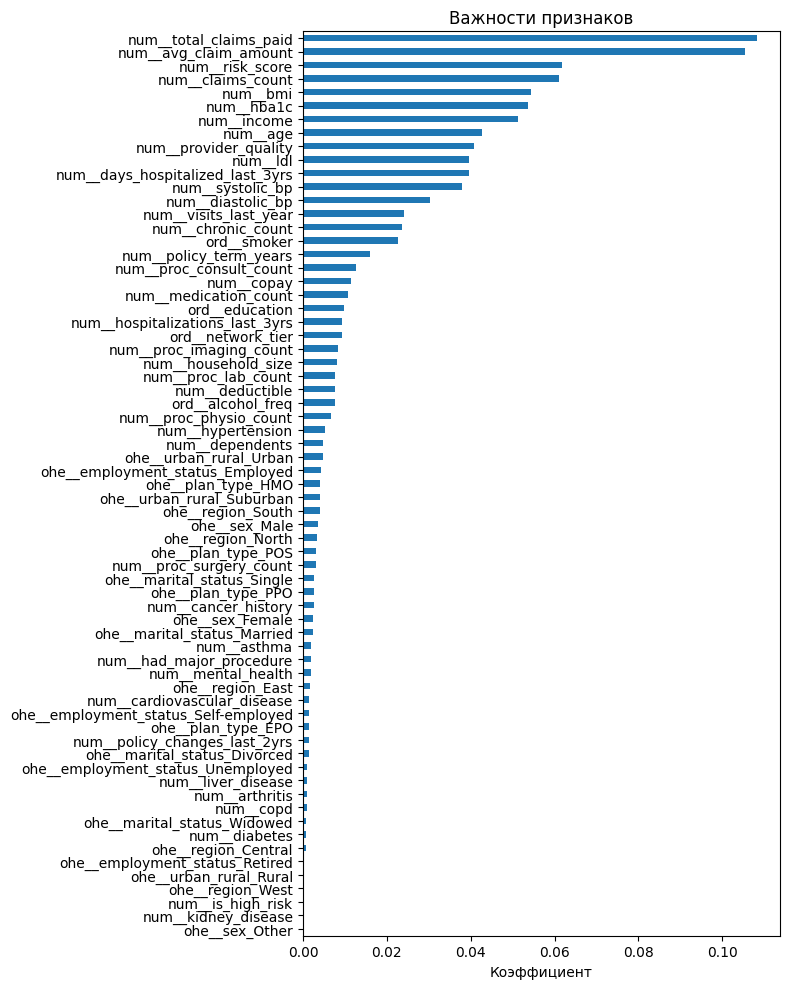

In [100]:
lgbm_pipe.fit(X_train, y_train)
#имена признаков после препроцессинга 
feature_names = lgbm_pipe.named_steps["prep"].get_feature_names_out()

# переводим в Series и сортируем по значению
importance = pd.Series((lgbm_pipe.named_steps["model"].feature_importances_ / lgbm_pipe.named_steps["model"].feature_importances_.sum()), 
                       index=feature_names).sort_values() #тут мы делим, чтобы на графике на оси Х были коэффициенты, а не абсолютные числа

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [101]:
importance_table = pd.DataFrame({
    "feature": feature_names,
    "importance": lgbm_pipe.named_steps["model"].feature_importances_ / lgbm_pipe.named_steps["model"].feature_importances_.sum(),
}).sort_values("importance", ascending=False)

importance_table.head(10)

,feature,importance
21,num__total_claims_paid,0.108333
20,num__avg_claim_amount,0.105333
18,num__risk_score,0.061667
19,num__claims_count,0.061000
4,num__bmi,0.054333
12,num__hba1c,0.053667
1,num__income,0.051333
0,num__age,0.042667
17,num__provider_quality,0.040667
7,num__days_hospitalized_last_3yrs,0.039667


Бустинг гораздо лучше распределил важность признаков, чем случайный лес или дерево решений. Самые важные признаки: total_claims_paid, avg_claim_amount, risk_score. 

1.6 Финальное сравнение метрик 

In [102]:
models = {
      "dummy":  DummyRegressor(strategy="median"),
      "linear": LinearRegression(),
      "tree":   DecisionTreeRegressor(random_state=SEED, max_depth=4),
      "forest": RandomForestRegressor(random_state=SEED, n_jobs=-1),
      "lgbm":   LGBMRegressor(random_state=SEED),
  }
results = {}
for name, model in models.items():
    pipe = Pipeline([("prep", get_preprocessor(X_train)), ("model", model)])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv_KFold, scoring=scoring)
    results[name] = {m.replace("neg_", ""): (-cv_res[f"test_{m}"].mean() if m.startswith("neg_") else cv_res[f"test_{m}"].mean().round(3)) for m in scoring }

results_df = pd.DataFrame(results)

print(results_df.T)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003609 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2394
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3014.539480


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003367 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3016.241110


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003447 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2393
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2998.241664


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003249 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2396
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3000.553826


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003425 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2994.759390
        root_mean_squared_error  mean_absolute_error     r2
dummy               3257.848568          1824.384985 -0.088
linear              1863.791422          1130.888990  0.643
tree                1878.868602          1122.180545  0.637
forest              1740.619330          1000.195553  0.689
lgbm                1727.496693           964.087789  0.694


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


ВЫВОД: 

Если сравнивать метрики нормальных моделей с dummy, то очевидно превосходство первых. Сильнее всего оказались ансамблевые модели: случайный лес и бустинг. Они превосходят как линейную регрессию, так и одиночное дерево. Я вижу дальнейший рост метрик от следующих действий: масштабирование и логарифмирование (много признаков имеют правый хвост) для линейной регрессии и подбор гиперпараметров для бустинга. 